In [1]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Generate deterministic seed using username
username = "konda.rithvika"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed:", seed)


Seed: 2226785795


In [2]:
class MyKMeans:
    def __init__(self, k=3, max_iters=200, tol=1e-4, random_state=None):
        """
        Initialize the KMeans clustering model.
        Parameters
        ----------
        k : int, default=3
            The number of clusters.
        max_iters : int, default=200
            Maximum number of iterations for convergence.
        tol : float, default=1e-4
            Tolerance for centroid convergence.
        random_state : int, optional
            Random seed for reproducibility.
        """
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.random_state = random_state
        self.centroids = None
        self.labels_ = None

    def fit(self, X):
        """
        Fit the KMeans model to the dataset X.
        Parameters
        ----------
        X : ndarray or DataFrame, shape (n_samples, n_features)
            Training data.
        """
        if isinstance(X, pd.DataFrame):
            X = X.values

        np.random.seed(self.random_state)

        random_indices = np.random.choice(X.shape[0], self.k, replace=False)
        self.centroids = X[random_indices]

        for _ in range(self.max_iters):
            labels = self._assign_clusters(X)
            new_centroids = np.array([X[labels == j].mean(axis=0) for j in range(self.k)])
            if np.all(np.abs(self.centroids - new_centroids) < self.tol):
                break
            self.centroids = new_centroids

        self.labels_ = labels

    def predict(self, X):
        """
        Predict the closest cluster for each sample in X.
        Parameters
        ----------
        X : ndarray or DataFrame, shape (n_samples, n_features)
            New data points.
        Returns
        -------
        labels : ndarray, shape (n_samples,)
            Index of the cluster each sample belongs to.
        """
        if isinstance(X, pd.DataFrame):
            X = X.values
        return self._assign_clusters(X)

    def getCost(self, X):
        """
        Compute the total within-cluster sum of squares (WCSS).
        Parameters
        ----------
        X : ndarray or DataFrame, shape (n_samples, n_features)
            Input data.
        Returns
        -------
        cost : float
            Sum of squared distances of samples to their closest cluster center.
        """
        if isinstance(X, pd.DataFrame):
            X = X.values
        distances = np.min(self._calculate_distances(X, self.centroids), axis=1)
        return np.sum(distances ** 2)

    def _assign_clusters(self, X):
        """
        Assign each data point to the nearest centroid.
        Parameters
        ----------
        X : ndarray, shape (n_samples, n_features)
        Returns
        -------
        labels : ndarray, shape (n_samples,)
            Cluster indices for each data point.
        """
        distances = self._calculate_distances(X, self.centroids)
        return np.argmin(distances, axis=1)

    def _calculate_distances(self, X, centroids):
        """
        Compute Euclidean distance from each point to each centroid.
        """
        distances = np.zeros((X.shape[0], self.k))
        for idx, centroid in enumerate(centroids):
            distances[:, idx] = np.linalg.norm(X - centroid, axis=1)
        return distances


In [3]:
# Load dataset
data = pd.read_csv("Clustering_dataset.csv")
data = data.drop(columns=["CustomerID"])  # Drop ID

# Fill 'Genre' and map to binary
data["Genre"] = data["Genre"].fillna(data["Genre"].mode()[0])
data["Genre"] = data["Genre"].map({"Male": 0, "Female": 1})

# Fill missing numerical values
for col in data.columns:
    data[col] = data[col].fillna(data[col].median())

# Make copies
data_unscaled = data.copy()
data_scaled = pd.DataFrame(StandardScaler().fit_transform(data), columns=data.columns)
K_range = range(2, 11)


In [4]:
# X_unscaled = data_unscaled.values

# kmeans_unscaled = MyKMeans(k=6, random_state=seed)
# kmeans_unscaled.fit(X_unscaled)

# labels_unscaled = kmeans_unscaled.predict(X_unscaled)
# data_unscaled['Cluster'] = labels_unscaled

# cost_unscaled = kmeans_unscaled.getCost(X_unscaled)


In [5]:
# wcss_unscaled = []
# K_range = range(2, 11)

# for k in K_range:
#     model = MyKMeans(k=k, random_state=seed)
#     model.fit(X_unscaled)
#     wcss_unscaled.append(model.getCost(X_unscaled))

# plt.figure(figsize=(8, 6))
# plt.plot(K_range, wcss_unscaled, marker='o', linestyle='--')
# plt.title("Elbow Method (Unscaled Data)")
# plt.xlabel("k")
# plt.ylabel("WCSS")
# plt.show()


In [6]:
# silhouette_unscaled = []

# for k in K_range:
#     model = MyKMeans(k=k, random_state=seed)
#     model.fit(X_unscaled)
#     score = silhouette_score(X_unscaled, model.labels_)
#     silhouette_unscaled.append(score)

# plt.figure(figsize=(8, 6))
# plt.plot(K_range, silhouette_unscaled, marker='o', linestyle='--', color='green')
# plt.title("Silhouette Score (Unscaled Data)")
# plt.xlabel("k")
# plt.ylabel("Silhouette Score")
# plt.show()

# print(f"Best k (Unscaled) by Silhouette: {K_range[np.argmax(silhouette_unscaled)]}")


In [7]:
X_scaled = data_scaled.values

kmeans_scaled = MyKMeans(k=6, random_state=seed)
kmeans_scaled.fit(X_scaled)

labels_scaled = kmeans_scaled.predict(X_scaled)
data_scaled['Cluster'] = labels_scaled

cost_scaled = kmeans_scaled.getCost(X_scaled)


k=2, WCSS=590.976136
k=3, WCSS=495.139697
k=4, WCSS=404.452274
k=5, WCSS=354.949518
k=6, WCSS=300.737391
k=7, WCSS=268.302352
k=8, WCSS=259.327416
k=9, WCSS=246.651398
k=10, WCSS=203.838540


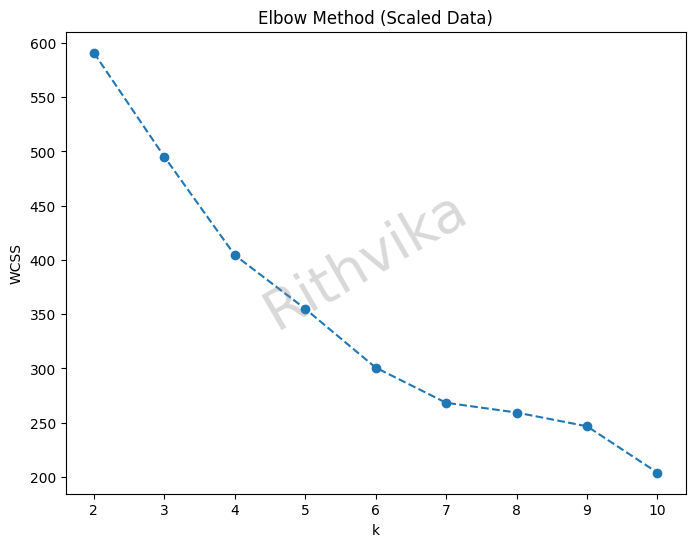

In [8]:
wcss_scaled = []
# K_range = (1,11)

for k in K_range:
    model = MyKMeans(k=k, random_state=seed)
    model.fit(X_scaled)
    cost_k = model.getCost(X_scaled)
    print(f"k={k}, WCSS={cost_k:.6f}")
    wcss_scaled.append(cost_k)
    # wcss_scaled.append(model.getCost(X_scaled))

plt.figure(figsize=(8, 6))
plt.plot(K_range, wcss_scaled, marker='o', linestyle='--')
plt.title("Elbow Method (Scaled Data)")
plt.xlabel("k")
plt.ylabel("WCSS")
plt.text(0.5, 0.5, 'Rithvika',
         transform=plt.gcf().transFigure,
         fontsize=40, color='gray', alpha=0.3,
         ha='center', va='center', rotation=30)

plt.show()


- Optimal k (Scaled) by elbow: 7

k=2, silhouette score=0.246813
k=3, silhouette score=0.244257
k=4, silhouette score=0.266393
k=5, silhouette score=0.289093
k=6, silhouette score=0.313168
k=7, silhouette score=0.323643
k=8, silhouette score=0.281737
k=9, silhouette score=0.255196
k=10, silhouette score=0.305217


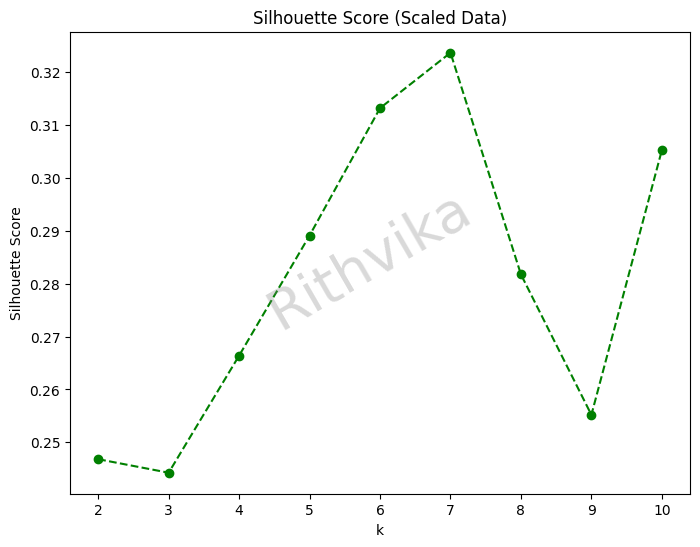

Optimal k (Scaled) by Silhouette: 7


In [9]:
silhouette_scaled = []

for k in K_range:
    model = MyKMeans(k=k, random_state=seed)
    model.fit(X_scaled)
    score = silhouette_score(X_scaled, model.labels_)
    print(f"k={k}, silhouette score={score:.6f}")
    silhouette_scaled.append(score)

plt.figure(figsize=(8, 6))
plt.plot(K_range, silhouette_scaled, marker='o', linestyle='--', color='green')
plt.title("Silhouette Score (Scaled Data)")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.text(0.5, 0.5, 'Rithvika',
         transform=plt.gcf().transFigure,
         fontsize=40, color='gray', alpha=0.3,
         ha='center', va='center', rotation=30)
plt.show()


print(f"Optimal k (Scaled) by Silhouette: {K_range[np.argmax(silhouette_scaled)]}")


### 1. Elbow Method (WCSS plot)

- The elbow is typically chosen where the decrease in WCSS slows down significantly.

- From first plot, the elbow appears around k = 6 to 7, since after that point, the reduction in WCSS becomes less steep.

### 2. Silhouette Score

- The Silhouette Score measures how well-separated and cohesive clusters are (ranges between -1 and 1, with higher being better).

- From the second plot, the highest silhouette score is at k = 7 (≈ 0.325).

- There’s also a relatively good score at k = 6 , but k = 7 is clearly the peak.

---

- Optimal k is likely 7.

- Elbow method suggests 6-7.

- Silhouette method peaks at 7.

In [10]:
# ## Using Standard KMEANS
# silhouette_scores = []
# K = range(2, 11)
# from sklearn.cluster import KMeans

# for k in K:
#     kmeans = KMeans(n_clusters=k, max_iter=100, random_state=seed)
#     kmeans.fit(X_scaled)
#     labels = kmeans.predict(X_scaled)

#     score = silhouette_score(X_scaled, labels)
#     silhouette_scores.append(score)

# plt.plot(K, silhouette_scores, 'bo-')
# plt.xlabel('k')
# plt.ylabel('Silhouette Score')
# plt.title('Silhouette Method')
# plt.show()

# # Print scores
# for k, score in zip(K, silhouette_scores):
#     print(f"k={k}, silhouette score={score:.3f}")

In [11]:
# Using Standard KMeans

# import matplotlib.pyplot as plt
# from sklearn.cluster import KMeans
# from sklearn.metrics import silhouette_score

# # --- Elbow Method ---
# wcss = []
# K = range(1, 10)
# for k in K:
#     kmeans = KMeans(n_clusters=k, max_iter=100, random_state=seed)
#     kmeans.fit(X_scaled)
#     wcss.append(kmeans.inertia_)
#     print(f"k={k}, WCSS={wcss[-1]}")

# plt.plot(K, wcss, 'bx-')
# plt.xlabel('k')
# plt.ylabel('WCSS')
# plt.title('Elbow Method')
# plt.show()